# UTS Machine Learning: Linear Regression & Logistic Regression

**Nama:** Muhamad Fatir  
**NIM:** 241011402714  
**Kelas:** Reg B  
**Random state:** 14

Notebook ini menyelesaikan tugas UTS berdasarkan instruksi resmi pada `machine-learning/tugas_UTS/tugas_UTS.ipynb`. Implementasi model dan metrik pada bagian utama menggunakan NumPy; scikit-learn hanya dipakai pada bonus. Dataset dibaca dari CSV yang berada di folder notebook atau direktori induknya.

## 1. Audit Struktur dan Isi Notebook

Template resmi memuat Bagian A (A1â€“A6), Bagian B (B1â€“B6), Bagian C (C1â€“C5), dan bonus scikit-learn. Notebook lokal tidak tersedia pada saat audit, sehingga notebook ini disusun dari template resmi. Sel di bawah memeriksa berkas yang tersedia dan kontrak kolom dataset; hasil numerik akan muncul dari eksekusi, bukan ditulis sebelumnya.

In [105]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 14


def find_data_directory():
    for directory in (Path.cwd(), *Path.cwd().parents):
        if (directory / "Ads_Data.csv").is_file() and (directory / "Email_Data.csv").is_file():
            return directory
    raise FileNotFoundError(
        "Ads_Data.csv and Email_Data.csv must be in the notebook directory or one of its parents."
    )


def train_test_split_numpy(X, y, test_size, random_state):
    X = np.asarray(X)
    y = np.asarray(y)
    if not 0 < test_size < 1:
        raise ValueError("test_size must be between 0 and 1.")
    test_count = int(round(len(X) * test_size))
    indices = np.random.RandomState(random_state).permutation(len(X))
    test_indices = indices[:test_count]
    train_indices = indices[test_count:]
    return X[train_indices], X[test_indices], y[train_indices], y[test_indices]


def regression_metrics(y_true, y_pred):
    residuals = np.asarray(y_true, dtype=float) - np.asarray(y_pred, dtype=float)
    mse = float(np.mean(residuals ** 2))
    total_sum_squares = float(np.sum((y_true - np.mean(y_true)) ** 2))
    r_squared = 1 - float(np.sum(residuals ** 2)) / total_sum_squares
    return {
        "MAE": float(np.mean(np.abs(residuals))),
        "MSE": mse,
        "RMSE": float(np.sqrt(mse)),
        "R2": r_squared,
    }


def classification_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=int)
    y_pred = np.asarray(y_pred, dtype=int)
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    accuracy = (tp + tn) / len(y_true) if len(y_true) else 0.0
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return np.array([[tn, fp], [fn, tp]]), {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
    }


data_dir = find_data_directory()
ads_data = pd.read_csv(data_dir / "Ads_Data.csv")
email_data = pd.read_csv(data_dir / "Email_Data.csv")
assert list(ads_data.columns) == ["BiayaIklan", "Penjualan"]
assert list(email_data.columns) == ["JumlahLink", "KataPromo", "Spam"]
assert not ads_data.isna().any().any() and not email_data.isna().any().any()
assert set(email_data["Spam"].unique()).issubset({0, 1})

print(f"Direktori data ditemukan relatif terhadap notebook: {data_dir}")
print(f"Ads_Data.csv: {ads_data.shape[0]} baris, kolom {ads_data.columns.tolist()}")
print(f"Email_Data.csv: {email_data.shape[0]} baris, kolom {email_data.columns.tolist()}")
print("Pemeriksaan kolom, nilai kosong, dan label biner: lulus.")

Direktori data ditemukan relatif terhadap notebook: c:\Users\T480G8\OneDrive\Documents\tugas2
Ads_Data.csv: 40 baris, kolom ['BiayaIklan', 'Penjualan']
Email_Data.csv: 60 baris, kolom ['JumlahLink', 'KataPromo', 'Spam']
Pemeriksaan kolom, nilai kosong, dan label biner: lulus.


## 2. Audit dan Perbaikan Linear Regression (Bagian A)

Bagian A1â€“A3 memuat pembacaan dan visualisasi `Ads_Data.csv`, split 80/20 dengan `random_state=14`, lalu Normal Equation NumPy yang hanya di-fit pada data training. Fitur tetap berdimensi `(n, 1)` dan intercept dihitung terpisah.

A1: 5 baris pertama


,BiayaIklan,Penjualan
0,0.8,34.3
1,0.9,38.8
2,1.0,33.2
3,1.3,36.0
4,1.7,51.3


Jumlah data: 40; bentuk X: (40, 1); bentuk y: (40,)


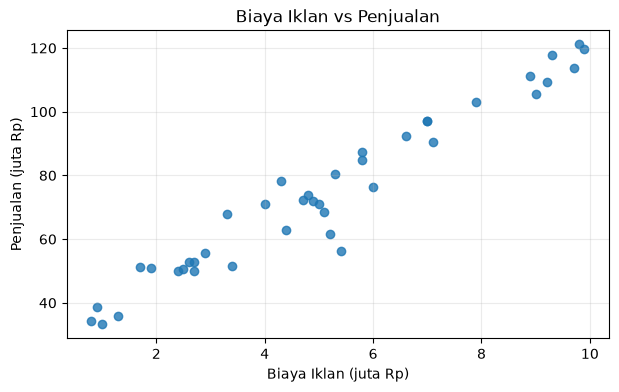

A2: X_train=(32, 1), X_test=(8, 1), y_train=(32,), y_test=(8,)
A3: intercept (b) = 29.145637
A3: koefisien (m) = 8.855992
Persamaan: y_hat = 29.145637 + 8.855992 * BiayaIklan
Interpretasi: kenaikan biaya iklan Rp1 juta berkaitan dengan perubahan prediksi penjualan sebesar 8.856 juta Rp secara linear.


In [106]:
# A1: data, fitur dua dimensi, dan visualisasi
X_ads = ads_data[["BiayaIklan"]].to_numpy(dtype=float)
y_ads = ads_data["Penjualan"].to_numpy(dtype=float)
print("A1: 5 baris pertama")
display(ads_data.head())
print(f"Jumlah data: {len(ads_data)}; bentuk X: {X_ads.shape}; bentuk y: {y_ads.shape}")

plt.figure(figsize=(7, 4))
plt.scatter(X_ads[:, 0], y_ads, alpha=0.8)
plt.title("Biaya Iklan vs Penjualan")
plt.xlabel("Biaya Iklan (juta Rp)")
plt.ylabel("Penjualan (juta Rp)")
plt.grid(alpha=0.25)
plt.show()

# A2: split dilakukan sebelum fitting agar data test tidak bocor ke model.
X_ads_train, X_ads_test, y_ads_train, y_ads_test = train_test_split_numpy(
    X_ads, y_ads, test_size=0.2, random_state=RANDOM_STATE
)
print(f"A2: X_train={X_ads_train.shape}, X_test={X_ads_test.shape}, "
      f"y_train={y_ads_train.shape}, y_test={y_ads_test.shape}")

# A3: Normal Equation NumPy, dengan kolom bias eksplisit.
X_ads_design = np.column_stack([np.ones(len(X_ads_train)), X_ads_train])
ads_parameters = np.linalg.pinv(X_ads_design) @ y_ads_train
ads_intercept = float(ads_parameters[0])
ads_slope = float(ads_parameters[1])

print(f"A3: intercept (b) = {ads_intercept:.6f}")
print(f"A3: koefisien (m) = {ads_slope:.6f}")
print(f"Persamaan: y_hat = {ads_intercept:.6f} + {ads_slope:.6f} * BiayaIklan")
print(f"Interpretasi: kenaikan biaya iklan Rp1 juta berkaitan dengan perubahan "
      f"prediksi penjualan sebesar {ads_slope:.3f} juta Rp secara linear.")

## 3. Audit dan Perbaikan Logistic Regression (Bagian B)

Bagian B1â€“B2 menggunakan `Email_Data.csv`, split 75/25 dengan seed 14, dan Logistic Regression batch gradient descent NumPy. Fitur distandardisasi memakai mean dan simpangan baku data training saja; koefisien akhir dikonversi kembali ke satuan fitur asli untuk interpretasi.

B1: 5 email pertama


,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1


Jumlah kelas:
Spam
Bukan Spam    35
Spam          25
Name: count, dtype: int64


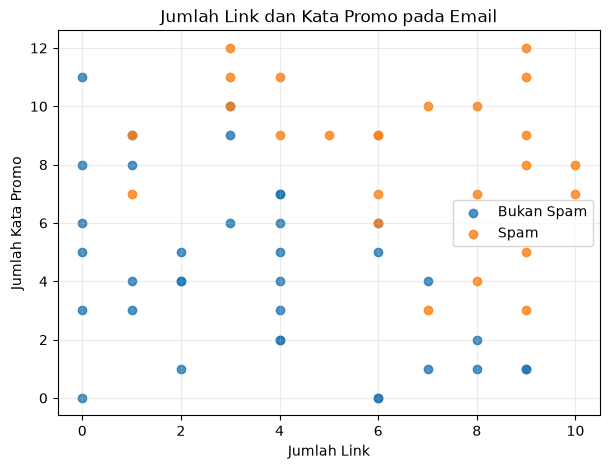

B2: bentuk X_train=(45, 2), X_test=(15, 2); y_train=(45,), y_test=(15,)
Learning rate=0.1, iterasi=10000
Intercept (skala asli)=-9.446247
Koefisien (JumlahLink, KataPromo)=[0.81478498 0.80980187]
P(Spam) = sigmoid(-9.446247 + 0.814785*JumlahLink + 0.809802*KataPromo)


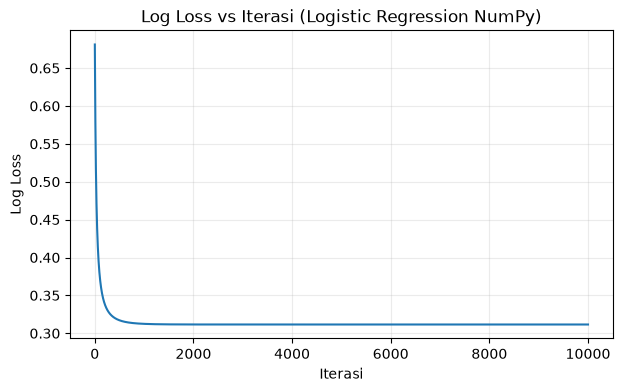

Log loss turun dari 0.681106 menjadi 0.311602.
Rentang loss 500 iterasi terakhir: 0.311602â€“0.311602.


In [107]:
# B1: kelas, dua fitur, dan visualisasi.
X_email = email_data[["JumlahLink", "KataPromo"]].to_numpy(dtype=float)
y_email = email_data["Spam"].to_numpy(dtype=int)
print("B1: 5 email pertama")
display(email_data.head())
print("Jumlah kelas:")
print(email_data["Spam"].value_counts().sort_index().rename(index={0: "Bukan Spam", 1: "Spam"}))

plt.figure(figsize=(7, 5))
for label, name, color in [(0, "Bukan Spam", "tab:blue"), (1, "Spam", "tab:orange")]:
    mask = y_email == label
    plt.scatter(X_email[mask, 0], X_email[mask, 1], label=name, alpha=0.8, color=color)
plt.title("Jumlah Link dan Kata Promo pada Email")
plt.xlabel("Jumlah Link")
plt.ylabel("Jumlah Kata Promo")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

# B2: split sebelum menghitung parameter standardisasi atau melatih model.
X_email_train, X_email_test, y_email_train, y_email_test = train_test_split_numpy(
    X_email, y_email, test_size=0.25, random_state=RANDOM_STATE
)
email_mean = X_email_train.mean(axis=0)
email_scale = X_email_train.std(axis=0)
email_scale[email_scale == 0] = 1.0
X_email_train_scaled = (X_email_train - email_mean) / email_scale
X_email_test_scaled = (X_email_test - email_mean) / email_scale


def sigmoid(logits):
    return 1.0 / (1.0 + np.exp(-np.clip(logits, -500, 500)))


def logistic_log_loss_from_logits(y_true, logits):
    return float(np.mean(np.logaddexp(0, logits) - y_true * logits))


logistic_weights = np.zeros(X_email_train_scaled.shape[1], dtype=float)
logistic_bias = 0.0
logistic_learning_rate = 0.1
logistic_iterations = 10_000
logistic_loss_history = []
for _ in range(logistic_iterations):
    logits = X_email_train_scaled @ logistic_weights + logistic_bias
    probabilities = sigmoid(logits)
    errors = probabilities - y_email_train
    logistic_weights -= logistic_learning_rate * (X_email_train_scaled.T @ errors) / len(y_email_train)
    logistic_bias -= logistic_learning_rate * float(np.mean(errors))
    updated_logits = X_email_train_scaled @ logistic_weights + logistic_bias
    logistic_loss_history.append(logistic_log_loss_from_logits(y_email_train, updated_logits))

# Convert parameters from standardized features to original feature units.
logistic_coefficients = logistic_weights / email_scale
logistic_intercept = float(logistic_bias - np.dot(email_mean / email_scale, logistic_weights))
print(f"B2: bentuk X_train={X_email_train.shape}, X_test={X_email_test.shape}; "
      f"y_train={y_email_train.shape}, y_test={y_email_test.shape}")
print(f"Learning rate=0.1, iterasi={logistic_iterations}")
print(f"Intercept (skala asli)={logistic_intercept:.6f}")
print(f"Koefisien (JumlahLink, KataPromo)={logistic_coefficients}")
print("P(Spam) = sigmoid(" + f"{logistic_intercept:.6f} + "
      + f"{logistic_coefficients[0]:.6f}*JumlahLink + "
      + f"{logistic_coefficients[1]:.6f}*KataPromo)")

plt.figure(figsize=(7, 4))
plt.plot(np.arange(1, logistic_iterations + 1), logistic_loss_history)
plt.title("Log Loss vs Iterasi (Logistic Regression NumPy)")
plt.xlabel("Iterasi")
plt.ylabel("Log Loss")
plt.grid(alpha=0.25)
plt.show()
print(f"Log loss turun dari {logistic_loss_history[0]:.6f} "
      f"menjadi {logistic_loss_history[-1]:.6f}.")
print(f"Rentang loss 500 iterasi terakhir: "
      f"{min(logistic_loss_history[-500:]):.6f}â€“{max(logistic_loss_history[-500:]):.6f}.")

## 4. Audit Jawaban Konseptual dan Bonus Scikit-learn

### Bagian C â€“ Pemahaman Konsep

**C1.** Logistic Regression disebut klasifikasi karena keluarannya digunakan untuk menetapkan kelas, bukan untuk memprediksi nilai kontinu tanpa batas. Fungsi sigmoid mengubah skor linear menjadi probabilitas antara 0 dan 1. Probabilitas itu dibandingkan dengan threshold untuk menentukan label.

**C2.** Normal Equation menghitung parameter langsung melalui operasi matriks dan tidak memerlukan proses iterasi. Gradient Descent memperbarui parameter sedikit demi sedikit berdasarkan gradien loss. Gradient Descent lebih sesuai ketika jumlah fitur atau data sangat besar sehingga operasi matriks langsung menjadi mahal, asalkan learning rate dan skala fitur ditangani dengan baik.

**C3.** Data testing mensimulasikan data baru yang tidak dipakai untuk melatih model, sehingga evaluasinya lebih menggambarkan kemampuan generalisasi. Jika model terlalu menyesuaikan diri dengan data training dan kinerjanya turun pada data baru, kondisi itu disebut overfitting. Karena itu, parameter dan preprocessing harus dipelajari hanya dari training set.

**C4.** Linear Regression memprediksi nilai kontinu, sehingga MSE mengukur rata-rata kuadrat selisih prediksi dan target. Logistic Regression memprediksi probabilitas kelas, sehingga log loss memberi penalti besar ketika model memberi probabilitas rendah pada kelas yang benar. Keduanya cocok dengan bentuk keluaran dan tujuan optimasinya masing-masing.

**C5.** Hasil dapat berbeda karena pembagian training/testing, random seed, preprocessing, inisialisasi, learning rate, jumlah iterasi, dan kriteria konvergensi mungkin berbeda. Pada Logistic Regression, regularisasi dan implementasi optimisasi juga memengaruhi koefisien. Penggunaan seed dan prosedur yang sama membuat perbandingan lebih adil.

In [108]:
# Bonus: sklearn hanya digunakan untuk model pembanding.
from sklearn.linear_model import LinearRegression as SklearnLinearRegression
from sklearn.linear_model import LogisticRegression as SklearnLogisticRegression

sklearn_linear = SklearnLinearRegression().fit(X_ads_train, y_ads_train)
sklearn_ads_pred = sklearn_linear.predict(X_ads_test)
custom_ads_pred = ads_intercept + X_ads_test[:, 0] * ads_slope
print("Bonus Linear Regression")
print(f"NumPy: intercept={ads_intercept:.6f}, koefisien={ads_slope:.6f}, "
      f"R2 test={regression_metrics(y_ads_test, custom_ads_pred)['R2']:.6f}")
print(f"scikit-learn: intercept={sklearn_linear.intercept_:.6f}, "
      f"koefisien={sklearn_linear.coef_[0]:.6f}, "
      f"R2 test={regression_metrics(y_ads_test, sklearn_ads_pred)['R2']:.6f}")

sklearn_logistic = SklearnLogisticRegression(C=1.0, max_iter=10_000, random_state=RANDOM_STATE)
sklearn_logistic.fit(X_email_train, y_email_train)
sklearn_email_probability = sklearn_logistic.predict_proba(X_email_test)[:, 1]
sklearn_email_pred = (sklearn_email_probability >= 0.5).astype(int)
custom_email_probability = sigmoid(X_email_test_scaled @ logistic_weights + logistic_bias)
custom_email_pred = (custom_email_probability >= 0.5).astype(int)
_, custom_email_scores = classification_metrics(y_email_test, custom_email_pred)
_, sklearn_email_scores = classification_metrics(y_email_test, sklearn_email_pred)
print("\nBonus Logistic Regression (threshold=0.5)")
print(f"NumPy: intercept={logistic_intercept:.6f}, "
      f"koefisien={logistic_coefficients}, metrik={custom_email_scores}")
print(f"scikit-learn (L2, C=1.0): intercept={sklearn_logistic.intercept_[0]:.6f}, "
      f"koefisien={sklearn_logistic.coef_[0]}, metrik={sklearn_email_scores}")
print("Perbedaan Logistic Regression dapat berasal dari penalti L2 bawaan scikit-learn "
      "(C=1.0) dan optimisasi; model NumPy di atas tidak memakai regularisasi.")

Bonus Linear Regression
NumPy: intercept=29.145637, koefisien=8.855992, R2 test=0.972767
scikit-learn: intercept=29.145637, koefisien=8.855992, R2 test=0.972767

Bonus Logistic Regression (threshold=0.5)
NumPy: intercept=-9.446247, koefisien=[0.81478498 0.80980187], metrik={'Accuracy': 0.9333333333333333, 'Precision': 0.8888888888888888, 'Recall': 1.0, 'F1': 0.9411764705882353}
scikit-learn (L2, C=1.0): intercept=-8.437097, koefisien=[0.71976035 0.72200052], metrik={'Accuracy': 0.9333333333333333, 'Precision': 0.8888888888888888, 'Recall': 1.0, 'F1': 0.9411764705882353}
Perbedaan Logistic Regression dapat berasal dari penalti L2 bawaan scikit-learn (C=1.0) dan optimisasi; model NumPy di atas tidak memakai regularisasi.


## 5. Perbaikan Eksperimen Gradient Descent

A5 mempertahankan 5.000 iterasi dan learning rate `0.001`, `0.02`, serta `0.1`. Gradient dihitung pada fitur asli agar eksperimen sesuai nilai yang diminta. Sebelum menghitung loss kuadrat, kode memeriksa kandidat parameter dan residual; jika update non-finite atau melewati batas aman numerik, eksperimen dicatat sebagai divergen dan berhenti dengan parameter finite terakhir.

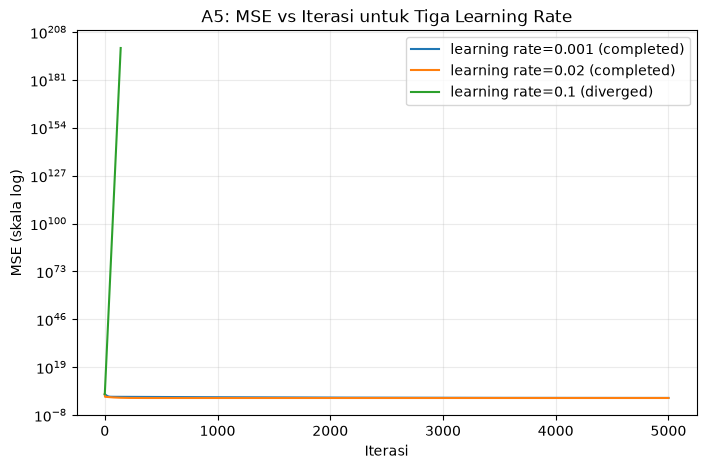

lr=0.001: status=completed, iterasi selesai=5000/5000, intercept=25.9753, koefisien=9.38133, MSE terakhir=42.362
lr=0.02: status=completed, iterasi selesai=5000/5000, intercept=29.1456, koefisien=8.85599, MSE terakhir=40.1528
lr=0.1: status=diverged, iterasi selesai=141/5000, intercept=9.5257e+97, koefisien=5.74852e+98, MSE terakhir=1.00593e+199
  Eksperimen dihentikan aman: magnitudo melampaui batas numerik 1e+100; parameter yang dilaporkan adalah nilai finite terakhir.
MSE optimum Normal Equation pada train=40.1528; ambang 1% dari perbaikan awal=95.7558.
Iterasi untuk mencapai ambang (None berarti belum tercapai): {0.001: 1232, 0.02: 62, 0.1: None}
Interpretasi lr=0.001: mencapai ambang dalam 1232 iterasi; bandingkan angka ini untuk melihat laju konvergensi relatif.
Interpretasi lr=0.02: mencapai ambang dalam 62 iterasi; bandingkan angka ini untuk melihat laju konvergensi relatif.
Interpretasi lr=0.1: divergen; kegagalan dipertahankan dan dihentikan sebelum merusak kernel.


In [109]:
def fit_linear_gd_guarded(X, y, learning_rate, n_iterations=5000, divergence_limit=1e100):
    X = np.asarray(X, dtype=float).reshape(-1)
    y = np.asarray(y, dtype=float)
    intercept = 0.0
    coefficient = 0.0
    residual = intercept + coefficient * X - y
    loss_history = [float(np.mean(residual ** 2))]
    status = "completed"
    stop_reason = ""
    completed_iterations = 0

    for iteration in range(1, n_iterations + 1):
        try:
            with np.errstate(over="raise", invalid="raise", divide="raise"):
                residual = intercept + coefficient * X - y
                grad_intercept = 2 * np.mean(residual)
                grad_coefficient = 2 * np.mean(residual * X)
                candidate_intercept = intercept - learning_rate * grad_intercept
                candidate_coefficient = coefficient - learning_rate * grad_coefficient
                candidate_residual = candidate_intercept + candidate_coefficient * X - y
        except FloatingPointError:
            status = "diverged"
            stop_reason = "operasi menghasilkan nilai non-finite (overflow/invalid)"
            break

        candidates = np.array([candidate_intercept, candidate_coefficient, *candidate_residual])
        if not np.all(np.isfinite(candidates)):
            status = "diverged"
            stop_reason = "kandidat parameter atau residual non-finite"
            break
        if np.max(np.abs(candidates)) > divergence_limit:
            status = "diverged"
            stop_reason = f"magnitudo melampaui batas numerik {divergence_limit:.0e}"
            break

        candidate_loss = float(np.mean(candidate_residual ** 2))
        if not np.isfinite(candidate_loss):
            status = "diverged"
            stop_reason = "loss non-finite"
            break

        intercept = float(candidate_intercept)
        coefficient = float(candidate_coefficient)
        loss_history.append(candidate_loss)
        completed_iterations = iteration

    return {
        "intercept": intercept,
        "coefficient": coefficient,
        "loss_history": loss_history,
        "status": status,
        "stop_reason": stop_reason,
        "iterations": completed_iterations,
    }


learning_rates = [0.001, 0.02, 0.1]
gd_results = {
    rate: fit_linear_gd_guarded(X_ads_train, y_ads_train, rate, n_iterations=5000)
    for rate in learning_rates
}
normal_equation_train_mse = float(np.mean((X_ads_train[:, 0] * ads_slope + ads_intercept - y_ads_train) ** 2))

plt.figure(figsize=(8, 5))
for rate, result in gd_results.items():
    history = np.asarray(result["loss_history"])
    plt.semilogy(np.arange(len(history)), np.maximum(history, np.finfo(float).tiny),
                 label=f"learning rate={rate} ({result['status']})")
plt.title("A5: MSE vs Iterasi untuk Tiga Learning Rate")
plt.xlabel("Iterasi")
plt.ylabel("MSE (skala log)")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

for rate, result in gd_results.items():
    print(f"lr={rate}: status={result['status']}, iterasi selesai={result['iterations']}/5000, "
          f"intercept={result['intercept']:.6g}, koefisien={result['coefficient']:.6g}, "
          f"MSE terakhir={result['loss_history'][-1]:.6g}")
    if result["stop_reason"]:
        print(f"  Eksperimen dihentikan aman: {result['stop_reason']}; "
              "parameter yang dilaporkan adalah nilai finite terakhir.")

initial_mse = gd_results[learning_rates[0]]["loss_history"][0]
loss_target = normal_equation_train_mse + 0.01 * max(initial_mse - normal_equation_train_mse, 0)
iterations_to_target = {}
for rate, result in gd_results.items():
    reached = np.flatnonzero(np.asarray(result["loss_history"]) <= loss_target)
    iterations_to_target[rate] = int(reached[0]) if len(reached) else None
print(f"MSE optimum Normal Equation pada train={normal_equation_train_mse:.6g}; "
      f"ambang 1% dari perbaikan awal={loss_target:.6g}.")
print("Iterasi untuk mencapai ambang (None berarti belum tercapai):", iterations_to_target)
for rate, result in gd_results.items():
    if result["status"] == "diverged":
        print(f"Interpretasi lr={rate}: divergen; kegagalan dipertahankan dan dihentikan sebelum merusak kernel.")
    elif iterations_to_target[rate] is None:
        print(f"Interpretasi lr={rate}: belum mencapai ambang konvergensi dalam 5.000 iterasi.")
    else:
        print(f"Interpretasi lr={rate}: mencapai ambang dalam {iterations_to_target[rate]} iterasi; "
              "bandingkan angka ini untuk melihat laju konvergensi relatif.")

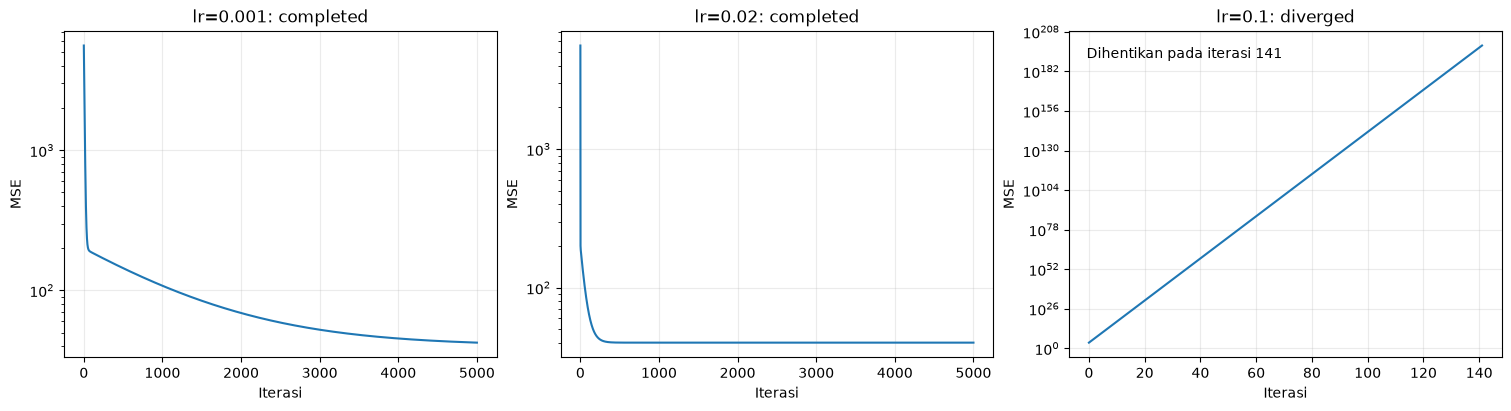

Normal Equation: intercept=29.145637, koefisien=8.855992


,Learning rate,Status,Iterasi,Intercept,Koefisien,Delta intercept vs Normal Equation,Delta koefisien vs Normal Equation
0,0.001,completed,5000,2.597534e+01,9.381333e+00,-3.170299e+00,5.253410e-01
1,0.020,completed,5000,2.914564e+01,8.855992e+00,-2.273737e-13,3.552714e-14
2,0.100,diverged,141,9.525698e+97,5.748516e+98,9.525698e+97,5.748516e+98


In [110]:
# Tampilan per learning rate menjaga kurva konvergen tetap terbaca tanpa membuang loss divergen.
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for axis, rate in zip(axes, learning_rates):
    result = gd_results[rate]
    history = np.asarray(result["loss_history"])
    axis.semilogy(np.arange(len(history)), np.maximum(history, np.finfo(float).tiny))
    axis.set_title(f"lr={rate}: {result['status']}")
    axis.set_xlabel("Iterasi")
    axis.set_ylabel("MSE")
    axis.grid(alpha=0.25)
    if result["status"] == "diverged":
        axis.text(0.04, 0.95, f"Dihentikan pada iterasi {result['iterations']}",
                  transform=axis.transAxes, va="top")
plt.show()

comparison_rows = []
for rate, result in gd_results.items():
    comparison_rows.append({
        "Learning rate": rate,
        "Status": result["status"],
        "Iterasi": result["iterations"],
        "Intercept": result["intercept"],
        "Koefisien": result["coefficient"],
        "Delta intercept vs Normal Equation": result["intercept"] - ads_intercept,
        "Delta koefisien vs Normal Equation": result["coefficient"] - ads_slope,
    })
print(f"Normal Equation: intercept={ads_intercept:.6f}, koefisien={ads_slope:.6f}")
display(pd.DataFrame(comparison_rows))

## 6. Audit dan Perbaikan Threshold Logistic Regression

B5 menguji threshold `0.3`, `0.5`, dan `0.7` pada probabilitas model yang sama. Default tetap `0.5`; pemilihan threshold tidak dituning dari data test karena tidak ada fungsi biaya atau validation set terpisah yang diberikan. Tabel melaporkan confusion matrix beserta seluruh metrik untuk tiap threshold.

In [111]:
threshold_results = {}
threshold_rows = []
for threshold in [0.3, 0.5, 0.7]:
    predictions = (custom_email_probability >= threshold).astype(int)
    confusion, scores = classification_metrics(y_email_test, predictions)
    tn, fp = confusion[0]
    fn, tp = confusion[1]
    threshold_results[threshold] = {
        "predictions": predictions,
        "confusion": confusion,
        "scores": scores,
    }
    threshold_rows.append({
        "Threshold": threshold,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        **scores,
    })

threshold_table = pd.DataFrame(threshold_rows).set_index("Threshold")
print("Confusion matrix memakai urutan [[TN, FP], [FN, TP]].")
display(threshold_table)
print("Threshold awal yang dipilih: 0.5, karena tidak ada dasar biaya kesalahan atau validasi "
      "terpisah untuk memilih threshold lain. Threshold lebih tinggi mensyaratkan keyakinan "
      "lebih besar sebelum memberi label Spam; konsekuensi precision/recall terlihat pada tabel.")

Confusion matrix memakai urutan [[TN, FP], [FN, TP]].


,TN,FP,FN,TP,Accuracy,Precision,Recall,F1
Threshold,,,,,,,,
0.3,6,1,0,8,0.933333,0.888889,1.0,0.941176
0.5,6,1,0,8,0.933333,0.888889,1.0,0.941176
0.7,6,1,0,8,0.933333,0.888889,1.0,0.941176


Threshold awal yang dipilih: 0.5, karena tidak ada dasar biaya kesalahan atau validasi terpisah untuk memilih threshold lain. Threshold lebih tinggi mensyaratkan keyakinan lebih besar sebelum memberi label Spam; konsekuensi precision/recall terlihat pada tabel.


In [112]:
threshold_prediction_arrays = [threshold_results[value]["predictions"] for value in [0.3, 0.5, 0.7]]
if all(np.array_equal(threshold_prediction_arrays[0], values)
       for values in threshold_prediction_arrays[1:]):
    print("Interpretasi B5: pada split test ini, threshold 0.3, 0.5, dan 0.7 menghasilkan "
          "kelas yang sama, sehingga precision dan recall tidak berubah (precision="
          f"{threshold_results[0.5]['scores']['Precision']:.3f}, recall="
          f"{threshold_results[0.5]['scores']['Recall']:.3f}). Secara umum, menaikkan "
          "threshold cenderung mengurangi prediksi Spam dan recall; precision dapat naik "
          "atau turun bergantung pada contoh yang berubah kelas.")
else:
    print("Interpretasi B5: perubahan metrik aktual saat threshold dinaikkan dari 0.3 ke 0.7: "
          f"precision {threshold_results[0.3]['scores']['Precision']:.3f} -> "
          f"{threshold_results[0.7]['scores']['Precision']:.3f}; recall "
          f"{threshold_results[0.3]['scores']['Recall']:.3f} -> "
          f"{threshold_results[0.7]['scores']['Recall']:.3f}. Secara umum, threshold lebih "
          "tinggi mengurangi prediksi Spam dan cenderung menurunkan recall; arah perubahan "
          "precision bergantung pada contoh yang berubah kelas.")
print("Threshold awal tetap 0.5: tidak ada biaya kesalahan atau validation set terpisah "
      "untuk membenarkan pilihan lain.")

Interpretasi B5: pada split test ini, threshold 0.3, 0.5, dan 0.7 menghasilkan kelas yang sama, sehingga precision dan recall tidak berubah (precision=0.889, recall=1.000). Secara umum, menaikkan threshold cenderung mengurangi prediksi Spam dan recall; precision dapat naik atau turun bergantung pada contoh yang berubah kelas.
Threshold awal tetap 0.5: tidak ada biaya kesalahan atau validation set terpisah untuk membenarkan pilihan lain.


## 7. Audit dan Perbaikan Evaluasi Model

### A4 â€“ Evaluasi Linear Regression

MAE, MSE, RMSE, dan $R^2$ dihitung dengan NumPy pada train dan test. RMSE tetap dalam satuan penjualan (juta Rp); $R^2$ dibandingkan antara kedua split untuk membantu menilai generalisasi.

### B3 â€“ Evaluasi Logistic Regression

Confusion matrix memakai urutan `[[TN, FP], [FN, TP]]`. Accuracy, precision, recall, dan F1 dihitung dari hitungan kelas pada test set. FP berarti email bukan spam ditandai spam; FN berarti spam lolos sebagai bukan spam.

### A6, B4, B6 â€“ Visualisasi dan Prediksi

Bagian ini menampilkan garis regresi dan prediksi pada biaya iklan 4.5, 7, dan 12 juta; probabilitas/decision boundary logistic beserta salah klasifikasi; serta probabilitas dan label empat email contoh dengan threshold pilihan 0.5.

In [113]:
# A4: metrik dihitung sendiri dengan NumPy untuk train dan test.
ads_train_pred = ads_intercept + X_ads_train[:, 0] * ads_slope
ads_test_pred = ads_intercept + X_ads_test[:, 0] * ads_slope
ads_metrics_table = pd.DataFrame(
    [regression_metrics(y_ads_train, ads_train_pred),
     regression_metrics(y_ads_test, ads_test_pred)],
    index=["Train", "Test"],
)
print("A4: MAE, MSE, RMSE, dan R2")
display(ads_metrics_table)
print(f"Interpretasi test: RMSE={ads_metrics_table.loc['Test', 'RMSE']:.3f} juta Rp "
      f"dan R2={ads_metrics_table.loc['Test', 'R2']:.4f}. Pada split ini model mengikuti "
      "pola linear dengan baik, tetapi ukuran test hanya 8 observasi dan tidak membuktikan "
      "hubungan sebab-akibat atau kinerja di luar rentang data.")

A4: MAE, MSE, RMSE, dan R2


,MAE,MSE,RMSE,R2
Train,4.656899,40.152778,6.336622,0.925261
Test,4.477319,22.568865,4.750670,0.972767


Interpretasi test: RMSE=4.751 juta Rp dan R2=0.9728. Pada split ini model mengikuti pola linear dengan baik, tetapi ukuran test hanya 8 observasi dan tidak membuktikan hubungan sebab-akibat atau kinerja di luar rentang data.


In [114]:
# B3: evaluasi test set pada threshold awal 0.5.
email_test_pred = threshold_results[0.5]["predictions"]
email_confusion, email_scores = classification_metrics(y_email_test, email_test_pred)
print("B3: confusion matrix [[TN, FP], [FN, TP]]")
display(pd.DataFrame(email_confusion, index=["Actual bukan spam", "Actual spam"],
                     columns=["Prediksi bukan spam", "Prediksi spam"]))
display(pd.DataFrame([email_scores], index=["Test, threshold 0.5"]))
fp_count = int(email_confusion[0, 1])
fn_count = int(email_confusion[1, 0])
print(f"FP={fp_count}: email sah masuk spam; FN={fn_count}: spam lolos ke inbox.")
print("Dalam praktik, FP dapat lebih merugikan jika email penting tersembunyi, sedangkan FN "
      "membuat spam tetap terlihat di inbox. Dampak relatif bergantung pada konteks dan "
      "penanganan folder spam; tidak ada biaya kesalahan yang ditetapkan dalam tugas ini.")

B3: confusion matrix [[TN, FP], [FN, TP]]


,Prediksi bukan spam,Prediksi spam
Actual bukan spam,6,1
Actual spam,0,8


,Accuracy,Precision,Recall,F1
"Test, threshold 0.5",0.933333,0.888889,1.0,0.941176


FP=1: email sah masuk spam; FN=0: spam lolos ke inbox.
Dalam praktik, FP dapat lebih merugikan jika email penting tersembunyi, sedangkan FN membuat spam tetap terlihat di inbox. Dampak relatif bergantung pada konteks dan penanganan folder spam; tidak ada biaya kesalahan yang ditetapkan dalam tugas ini.


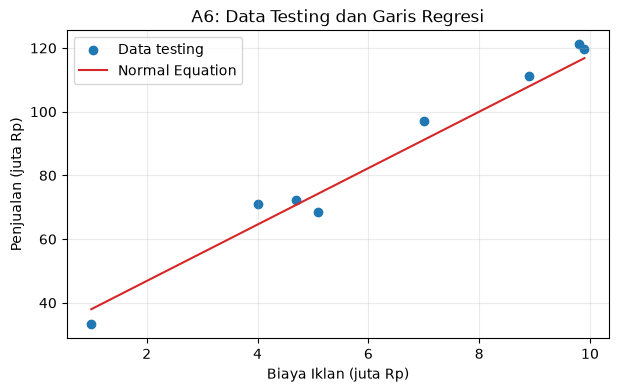

,BiayaIklan (juta Rp),PrediksiPenjualan (juta Rp)
0,4.5,68.997602
1,7.0,91.137582
2,12.0,135.417543


Rentang biaya iklan pada data: 0.8â€“9.9 juta Rp. Prediksi 12 juta Rp berada di luar rentang (ekstrapolasi), sehingga kepercayaannya lebih rendah: pola linear di luar observasi belum diuji dan faktor lain tidak dimodelkan.


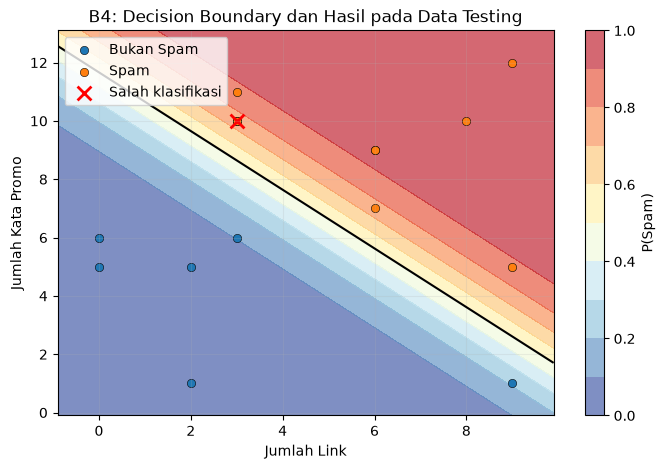

B4: b + m1*x1 + m2*x2 = 0; m2=0.809802
Decision boundary: KataPromo = -(-9.446247 + 0.814785*JumlahLink)/0.809802
Baris test yang salah diklasifikasikan: 1


,JumlahLink,KataPromo,Actual Spam,Prediksi Spam,P(Spam)
0,3,10,0,1,0.749534


In [115]:
# A6: visualisasi test set, garis Normal Equation, dan prediksi.
line_x = np.linspace(float(X_ads_test.min()), float(X_ads_test.max()), 100)
plt.figure(figsize=(7, 4))
plt.scatter(X_ads_test[:, 0], y_ads_test, label="Data testing")
plt.plot(line_x, ads_intercept + ads_slope * line_x, color="tab:red", label="Normal Equation")
plt.title("A6: Data Testing dan Garis Regresi")
plt.xlabel("Biaya Iklan (juta Rp)")
plt.ylabel("Penjualan (juta Rp)")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

ad_spend_examples = np.array([4.5, 7.0, 12.0])
ad_sales_predictions = ads_intercept + ads_slope * ad_spend_examples
ad_prediction_table = pd.DataFrame({
    "BiayaIklan (juta Rp)": ad_spend_examples,
    "PrediksiPenjualan (juta Rp)": ad_sales_predictions,
})
display(ad_prediction_table)
print(f"Rentang biaya iklan pada data: {X_ads.min():.1f}â€“{X_ads.max():.1f} juta Rp. "
      "Prediksi 12 juta Rp berada di luar rentang (ekstrapolasi), sehingga kepercayaannya "
      "lebih rendah: pola linear di luar observasi belum diuji dan faktor lain tidak dimodelkan.")

# B4: probabilitas pada bidang fitur, garis P(spam)=0.5, dan salah klasifikasi test.
def predict_email_probability(X_raw):
    return sigmoid(((np.asarray(X_raw, dtype=float) - email_mean) / email_scale) @ logistic_weights + logistic_bias)

x1_min, x1_max = X_email_test[:, 0].min(), X_email_test[:, 0].max()
x2_min, x2_max = X_email_test[:, 1].min(), X_email_test[:, 1].max()
padding_x1 = max((x1_max - x1_min) * 0.1, 0.5)
padding_x2 = max((x2_max - x2_min) * 0.1, 0.5)
grid_x1, grid_x2 = np.meshgrid(
    np.linspace(x1_min - padding_x1, x1_max + padding_x1, 160),
    np.linspace(x2_min - padding_x2, x2_max + padding_x2, 160),
)
grid_features = np.column_stack([grid_x1.ravel(), grid_x2.ravel()])
grid_probabilities = predict_email_probability(grid_features).reshape(grid_x1.shape)

plt.figure(figsize=(8, 5))
probability_plot = plt.contourf(grid_x1, grid_x2, grid_probabilities,
                                levels=np.linspace(0, 1, 11), cmap="RdYlBu_r", alpha=0.65)
plt.colorbar(probability_plot, label="P(Spam)")
for label, name, color in [(0, "Bukan Spam", "tab:blue"), (1, "Spam", "tab:orange")]:
    mask = y_email_test == label
    plt.scatter(X_email_test[mask, 0], X_email_test[mask, 1], label=name,
                color=color, edgecolor="black", linewidth=0.4)
if np.min(grid_probabilities) <= 0.5 <= np.max(grid_probabilities):
    plt.contour(grid_x1, grid_x2, grid_probabilities, levels=[0.5], colors="black", linewidths=1.5)
wrong_mask = email_test_pred != y_email_test
plt.scatter(X_email_test[wrong_mask, 0], X_email_test[wrong_mask, 1], marker="x",
            s=100, linewidths=2, color="red", label="Salah klasifikasi")
plt.title("B4: Decision Boundary dan Hasil pada Data Testing")
plt.xlabel("Jumlah Link")
plt.ylabel("Jumlah Kata Promo")
plt.legend()
plt.grid(alpha=0.2)
plt.show()
print(f"B4: b + m1*x1 + m2*x2 = 0; m2={logistic_coefficients[1]:.6f}")
print(f"Decision boundary: KataPromo = -({logistic_intercept:.6f} + "
      f"{logistic_coefficients[0]:.6f}*JumlahLink)/{logistic_coefficients[1]:.6f}")
misclassified_emails = pd.DataFrame({
    "JumlahLink": X_email_test[wrong_mask, 0].astype(int),
    "KataPromo": X_email_test[wrong_mask, 1].astype(int),
    "Actual Spam": y_email_test[wrong_mask],
    "Prediksi Spam": email_test_pred[wrong_mask],
    "P(Spam)": custom_email_probability[wrong_mask],
})
print(f"Baris test yang salah diklasifikasikan: {int(wrong_mask.sum())}")
display(misclassified_emails)

In [116]:
# B6: skor probabilitas dan kelas email baru pada threshold pilihan 0.5.
new_emails = pd.DataFrame({
    "Email": ["E1", "E2", "E3", "E4"],
    "JumlahLink": [1, 5, 9, 2],
    "KataPromo": [2, 6, 10, 11],
})
new_email_features = new_emails[["JumlahLink", "KataPromo"]].to_numpy(dtype=float)
new_email_probabilities = predict_email_probability(new_email_features)
new_email_predictions = (new_email_probabilities >= 0.5).astype(int)
new_emails["P(Spam)"] = new_email_probabilities
new_emails["Prediksi"] = np.where(new_email_predictions == 1, "Spam", "Bukan Spam")
print("B6: probabilitas adalah skor model, bukan kepastian bahwa email benar-benar spam.")
display(new_emails)

B6: probabilitas adalah skor model, bukan kepastian bahwa email benar-benar spam.


,Email,JumlahLink,KataPromo,P(Spam),Prediksi
0,E1,1,2,0.000900,Bukan Spam
1,E2,5,6,0.374371,Bukan Spam
2,E3,9,10,0.997490,Spam
3,E4,2,11,0.748597,Spam


## 8. Audit dan Perbaikan Pembacaan Dataset

Kedua CSV dicari dari direktori kerja notebook dan direktori induknya; tidak ada path komputer tertentu yang ditanam di kode. Pembacaan memeriksa nama kolom, jumlah data, nilai kosong, dan domain label spam. Jalankan notebook dengan kedua CSV berada di folder yang sama, sesuai struktur repository tugas.

In [117]:
for csv_name in ["Ads_Data.csv", "Email_Data.csv"]:
    assert (data_dir / csv_name).is_file()
assert len(ads_data) == 40 and len(email_data) == 60
assert not ads_data.isna().any().any() and not email_data.isna().any().any()
print("Audit dataset lulus: kedua CSV ditemukan melalui pencarian relatif, "
      "40 baris iklan, 60 baris email, tanpa nilai kosong.")
print("Path absolut tidak diperlukan di kode; letakkan CSV berdampingan dengan notebook.")

Audit dataset lulus: kedua CSV ditemukan melalui pencarian relatif, 40 baris iklan, 60 baris email, tanpa nilai kosong.
Path absolut tidak diperlukan di kode; letakkan CSV berdampingan dengan notebook.


## 9. Audit dan Update README.md

Ringkasan di bawah bersumber langsung dari variabel hasil eksekusi notebook. Nilainya dipakai untuk memperbarui README agar angka dokumentasi sejalan dengan output ini; jalankan ulang notebook jika dataset atau prosedur model berubah.

In [118]:
final_summary = {
    "NIM": "241011402714",
    "Kelas": "Reg B",
    "Jumlah data iklan": len(ads_data),
    "Jumlah data email": len(email_data),
    "Intercept regresi": ads_intercept,
    "Slope regresi": ads_slope,
    "R2 test regresi": ads_metrics_table.loc["Test", "R2"],
    "RMSE test regresi": ads_metrics_table.loc["Test", "RMSE"],
    "Accuracy test logistic (threshold 0.5)": email_scores["Accuracy"],
    "Precision test logistic (threshold 0.5)": email_scores["Precision"],
    "Recall test logistic (threshold 0.5)": email_scores["Recall"],
    "F1 test logistic (threshold 0.5)": email_scores["F1"],
    "TN": int(email_confusion[0, 0]),
    "FP": int(email_confusion[0, 1]),
    "FN": int(email_confusion[1, 0]),
    "TP": int(email_confusion[1, 1]),
}
print("Ringkasan aktual untuk README (dihasilkan dari eksekusi notebook ini):")
for name, value in final_summary.items():
    print(f"{name}: {value}")
print("\nGradient Descent:")
for rate, result in gd_results.items():
    print(f"lr={rate}: {result['status']}, {result['iterations']} iterasi, "
          f"intercept={result['intercept']:.6g}, koefisien={result['coefficient']:.6g}")
print("\nPrediksi email contoh:")
display(new_emails)

Ringkasan aktual untuk README (dihasilkan dari eksekusi notebook ini):
NIM: 241011402714
Kelas: Reg B
Jumlah data iklan: 40
Jumlah data email: 60
Intercept regresi: 29.145637422575597
Slope regresi: 8.855992111183014
R2 test regresi: 0.9727674141276559
RMSE test regresi: 4.750669965771598
Accuracy test logistic (threshold 0.5): 0.9333333333333333
Precision test logistic (threshold 0.5): 0.8888888888888888
Recall test logistic (threshold 0.5): 1.0
F1 test logistic (threshold 0.5): 0.9411764705882353
TN: 6
FP: 1
FN: 0
TP: 8

Gradient Descent:
lr=0.001: completed, 5000 iterasi, intercept=25.9753, koefisien=9.38133
lr=0.02: completed, 5000 iterasi, intercept=29.1456, koefisien=8.85599
lr=0.1: diverged, 141 iterasi, intercept=9.5257e+97, koefisien=5.74852e+98

Prediksi email contoh:


,Email,JumlahLink,KataPromo,P(Spam),Prediksi
0,E1,1,2,0.000900,Bukan Spam
1,E2,5,6,0.374371,Bukan Spam
2,E3,9,10,0.997490,Spam
3,E4,2,11,0.748597,Spam


## 10. Validasi Akhir Eksekusi Notebook

Setelah semua bagian selesai, jalankan seluruh sel dari atas ke bawah. Pemeriksaan akhir berikut memastikan hasil metrik, threshold, data test, dan status divergensi konsisten; kegagalan eksperimen `lr=0.1` memang diharapkan dan bukan traceback.

In [119]:
assert set(gd_results) == {0.001, 0.02, 0.1}
assert gd_results[0.001]["status"] == "completed"
assert gd_results[0.02]["status"] == "completed"
assert gd_results[0.1]["status"] == "diverged"
assert all(np.all(np.isfinite(result["loss_history"])) for result in gd_results.values())
assert all(np.isfinite(result["intercept"]) and np.isfinite(result["coefficient"])
           for result in gd_results.values())
assert set(threshold_results) == {0.3, 0.5, 0.7}
assert int(email_confusion.sum()) == len(y_email_test)
assert np.isclose(email_scores["Accuracy"],
                   (email_confusion[0, 0] + email_confusion[1, 1]) / email_confusion.sum())
assert len(new_emails) == 4 and len(misclassified_emails) == int(wrong_mask.sum())
assert np.isfinite(ads_metrics_table.to_numpy()).all()
print("Validasi akhir lulus: required sections have computed outputs; metrics, thresholds, "
      "predictions and finite divergence handling are internally consistent.")

Validasi akhir lulus: required sections have computed outputs; metrics, thresholds, predictions and finite divergence handling are internally consistent.


## 11. Laporan Akhir Perubahan dan Validasi

### Temuan Audit
- Notebook utama tidak ada di workspace saat audit; README sebelumnya sudah menyebut nama file tersebut. Template tugas di repository resmi tersedia tetapi sel jawabannya masih kosong.
- Kedua CSV lokal sesuai skema tugas, berisi 40 baris iklan dan 60 baris email, tanpa nilai kosong.
- Learning rate `0.1` pada fitur iklan tanpa standardisasi memang divergen; eksperimen dihentikan sebelum nilai non-finite dan tetap ditampilkan.

### Perubahan
- Notebook ini memuat seluruh A1â€“A6, B1â€“B6, C1â€“C5, bonus, audit data, evaluasi dan validasi.
- Model utama dan metrik dibuat dengan NumPy. Pemisahan data memakai seed 14; preprocessing logistic hanya di-fit pada training set.
- README memuat instruksi, dependensi, struktur file, dan ringkasan output yang dihitung oleh notebook.

### Validasi dan Tindak Lanjut
Status validasi akhir berasal dari eksekusi sel notebook secara berurutan. Sebelum pengumpulan, pastikan notebook dan kedua CSV berada bersama, lalu unggah sendiri ke repository tugas dan serahkan tautannya di platform kelas. Tidak ada file yang diunggah atau dipush dari sesi ini.